# Экзамен

Выполнил: Уразбаев Артур

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1

Считываем данные в DataFrame.

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

Проверяем количество строк и столбцов:

In [3]:
events.shape

(29710, 38)

Выводим отдельные ячейки из примера:

In [4]:
events.iloc[:10,[2,3,4,9,12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


### 2

Сгруппируем игры по их id.

In [5]:
games = events.groupby('Game ID').agg(**{
    'Date': ('Date', 'first'),
    'Away Team': ('Away Team', 'first'),
    'Home Team': ('Home Team', 'first'),
    'Away Score': ('Cumulated Away Score', 'max'),
    'Home Score': ('Cumulated Home Score', 'max'),
    'Outcome': ('Period', 'max'),
})
games['Outcome'] = games['Outcome'].map({3: 'Final', 4: 'Final/OT', 5: 'Final/2OT'})

In [6]:
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')

Выведем ячейки из примера:

In [7]:
games.iloc[-5:,-4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


### 3

In [8]:
def gameInfo(gameId):
    home_team = games.loc[gameId, 'Home Team']
    away_team = games.loc[gameId, 'Away Team']
    home_score = games.loc[gameId, 'Home Score']
    away_score = games.loc[gameId, 'Away Score']
    outcome = games.loc[gameId, 'Outcome']
    date = games.loc[gameId, 'Date']
    return (f"{home_team} - {away_team} ({home_score} - {away_score}, {outcome}, {date})")

Тестируем вывод функции:

In [9]:
gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [10]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

In [11]:
gameInfo(2025030186)

'Anaheim Ducks - Edmonton Oilers (5 - 2, Final, 2026-04-30)'

### 4

In [12]:
games['Total Score'] = games['Home Score'] + games['Away Score']

Выводим статистики:

In [13]:
games['Total Score'].describe()

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

### 5

Text(0, 0.5, 'Число матчей')

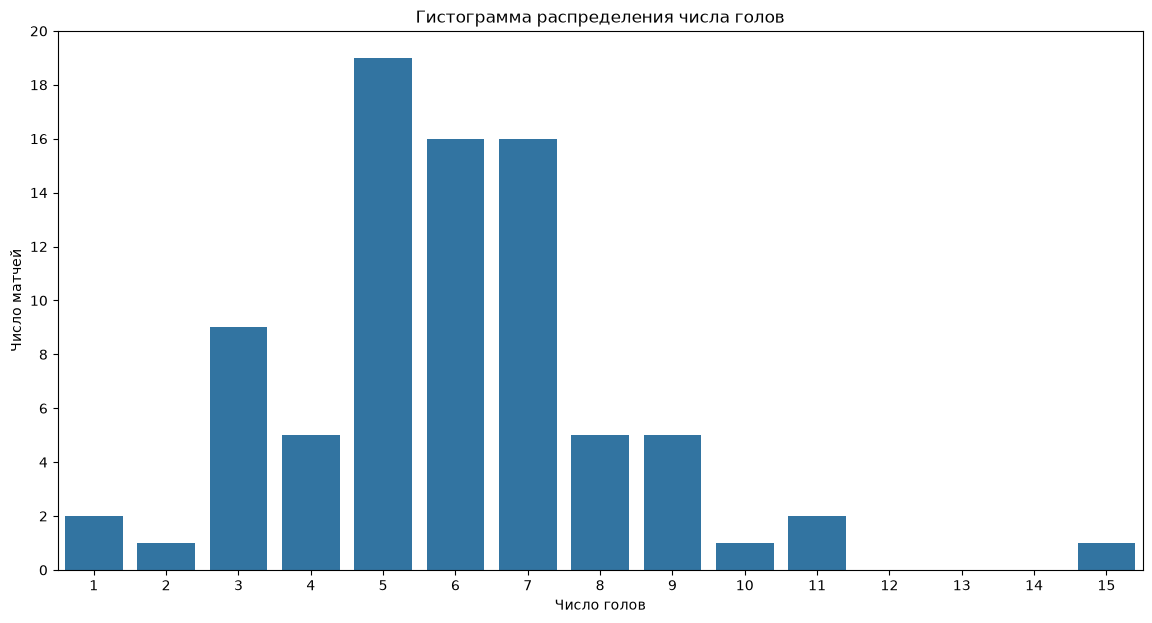

In [14]:
plt.figure(figsize=(14, 7))
sns.countplot(x=games['Total Score'], order=range(games['Total Score'].min(), games['Total Score'].max() + 1))
plt.yticks(range(0, games['Total Score'].value_counts().max() + 2, 2))
plt.title('Гистограмма распределения числа голов')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')

Самое частое число голов - 5, таких матчей 19. В самом результативном матче было забито 15 голов (такой всего один), при этом ни в одном матче не было забито ровно 12,13 или 14 голов. В целом распределение отдаленно похоже на нормальное, однако столбец 4 слишком выделяется, а столбец 15 выглядит как выброс (это все вызвано тем, что наблюдений слишком мало - 82).

### 6

Самые нерезультативные матчи:

In [15]:
min_goals_games = games.index[games['Total Score'] == games['Total Score'].min()]
for game in min_goals_games:
    print(gameInfo(game))

Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)


Самые результативные матчи:

In [16]:
max_goals_games = games.index[games['Total Score'] == games['Total Score'].max()]
for game in max_goals_games:
    print(gameInfo(game))

Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


### 7

Объединим названия всех столбцов с игроками в одном массиве.

In [17]:
player_columns = [c for c in events.columns if 'on the Ice #' in c or 'Goalie' in c]
player_columns

["Away Team's Player on the Ice #1",
 "Away Team's Player on the Ice #2",
 "Away Team's Player on the Ice #3",
 "Away Team's Player on the Ice #4",
 "Away Team's Player on the Ice #5",
 "Away Team's Player on the Ice #6",
 "Away Team's Goalie",
 "Home Team's Player on the Ice #1",
 "Home Team's Player on the Ice #2",
 "Home Team's Player on the Ice #3",
 "Home Team's Player on the Ice #4",
 "Home Team's Player on the Ice #5",
 "Home Team's Player on the Ice #6",
 "Home Team's Goalie"]

В отдельной таблице соберем игроков из всех записей датафрейма events. В каждом столбце игрок на конкретной позиции в момент события из events.

In [18]:
players = events.melt(id_vars='Game ID', value_vars=player_columns)
players

,Game ID,variable,value
0,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
1,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
2,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
3,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
4,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
...,...,...,...
415935,2025030416,Home Team's Goalie,Carter Hart
415936,2025030416,Home Team's Goalie,Carter Hart
415937,2025030416,Home Team's Goalie,Carter Hart
415938,2025030416,Home Team's Goalie,Carter Hart


Добавим в games столбец с количеством игроков.

In [19]:
games['Player Count'] = players.groupby('Game ID')['value'].nunique()

Выведем инфу по играм с максимальным количсетвом игроков и само количество.

In [20]:
max_goals_games = games.index[games['Player Count'] == games['Player Count'].max()]
for game in max_goals_games:
    print(f"{gameInfo(game)} - {games.loc[game, 'Player Count']}")

Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16) - 40


### 8

Отберём события-броски: точные (shot-on-goal, goal) и неточные (missed-shot).

In [21]:
shots = events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])

Определим, в какие ворота бросали.

In [22]:
is_home = events['Team Making the Play'] == events['Home Team']
defends_left = events["Home Team's Defending Side"] == 'left'
goal_x = np.where(is_home == defends_left, 89, -89)

Посчитаем расстояние до ближайшей точки створа.

In [23]:
x = events['X Coordinate on the Ice Rink']
y = events['Y Coordinate on the Ice Rink']
dy = (y.abs() - 3).clip(lower=0)
events.loc[shots, 'Shot Length'] = np.sqrt((x - goal_x) ** 2 + dy ** 2)

Выведем ячейки из примера:

In [24]:
events[shots][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


### 9

Разделим броски на точные и неточные.

In [25]:
events['Shot'] = events['Play Type'].map({'shot-on-goal': 'on goal', 'goal': 'on goal', 'missed-shot': 'missed'})

Строим график, при этом (с учетом того, что выборки разные по размеру) выводим не количество, а плотность.

Text(-5.118134920634899, 0.5, 'Частота')

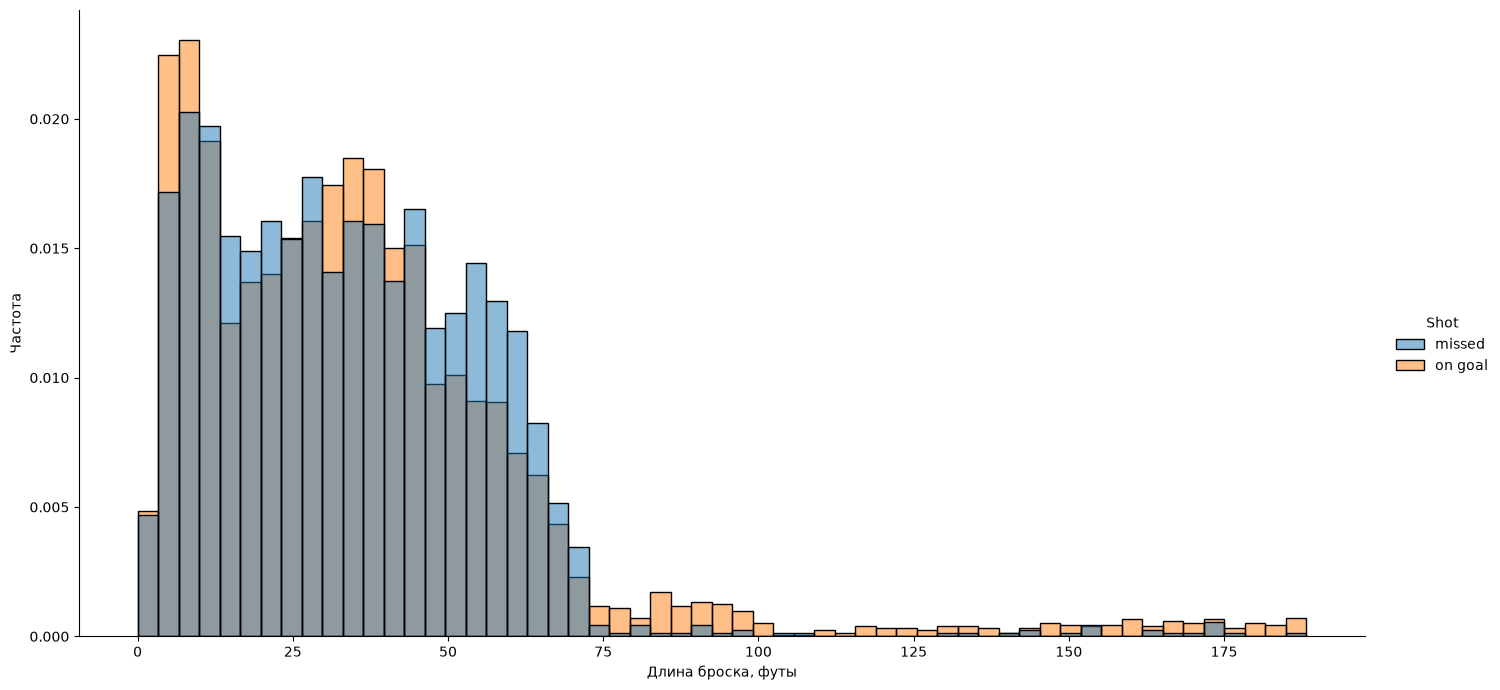

In [26]:
sns.displot(data=events, x='Shot Length', hue='Shot', stat='density', common_norm=False, height=7, aspect=2)
plt.xlabel('Длина броска, футы')
plt.ylabel('Частота')

С близкого расстояния (до 10 футов) и с 30–40 футов чаще бросают точно, а с 45–65 футов чаще промахиваются. Дальше 75 футов почти все броски точные. Возможно это связано с тем, что если дальний удар не точный, то он зачастую вообще не засчитывается как удар.

### 10

Посчитаем точные и неточные броски каждой команды в каждой игре. Заблокированные броски не учитываем: в столбце Shot у них NaN.

In [27]:
numshots = pd.crosstab([events['Game ID'], events['Team Making the Play']], events['Shot'])
numshots['Share of Shots on Goal'] = numshots['on goal'] / (numshots['on goal'] + numshots['missed'])
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
                                      ...   
2025030414  Vegas Golden Knights    0.583333
2025030415  Carolina Hurricanes     0.558140
            Vegas Golden Knights    0.510204
2025030416  Carolina Hurricanes     0.638889
            Vegas Golden Knights    0.594595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [28]:
numshots['Share of Shots on Goal'].describe()

count    164.000000
mean       0.639150
std        0.085000
min        0.352941
25%        0.582955
50%        0.638889
75%        0.688889
max        0.860465
Name: Share of Shots on Goal, dtype: float64

Средняя точность - 63%, минимальная - 35%, максимальная - 86%.

### 11

Посчитаем для каждой команды среднюю долю точных бросков за матч.

In [29]:
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()

Пять команд с самой высокой долей:

In [30]:
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706232
Philadelphia Flyers    0.683668
Dallas Stars           0.670142
Minnesota Wild         0.656099
Colorado Avalanche     0.652559
Name: Share of Shots on Goal, dtype: float64

Пять команд с самой низкой долей:

In [31]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554046
Utah Mammoth           0.599298
Carolina Hurricanes    0.614844
Tampa Bay Lightning    0.625713
Buffalo Sabres         0.625838
Name: Share of Shots on Goal, dtype: float64

Самые точные команды — Edmonton Oilers (70%) и Philadelphia Flyers (68%), самая неточная — Pittsburgh Penguins (55%). Pittsburgh заметно отстаёт даже от следующей за ним Utah Mammoth (59%). Остальные команды из двух списков укладываются в узкий диапазон от 61% до 67%, то есть по точности команды плей-офф отличаются не сильно.

### 12

Добавим в numshots число голов каждой команды в каждой игре.

In [32]:
events['Is Goal'] = events['Play Type'] == 'goal'
numshots['Goal'] = events.groupby(['Game ID', 'Team Making the Play'])['Is Goal'].sum()

Найдем среднее число бросков в створ и голов по играм для каждой команды.

In [33]:
avgshots = numshots.groupby('Team Making the Play')[['on goal', 'Goal']].mean()
avgshots.columns = ['Shot', 'Goal']
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.666667,3.250000
Boston Bruins,25.166667,2.000000
Buffalo Sabres,30.461538,3.307692
Carolina Hurricanes,31.631579,3.473684
Colorado Avalanche,32.153846,3.384615
Dallas Stars,31.000000,2.500000
Edmonton Oilers,28.333333,3.500000
Los Angeles Kings,25.250000,1.250000
Minnesota Wild,28.727273,3.727273


### 13

Text(0, 0.5, 'Среднее число голов за игру')

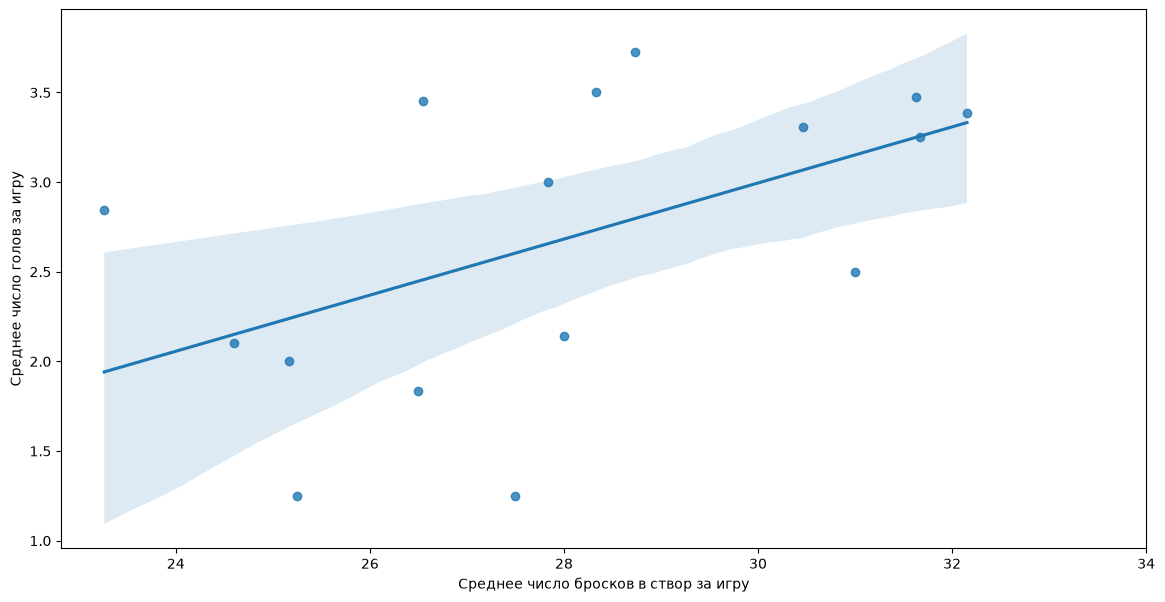

In [34]:
plt.figure(figsize=(14, 7))
sns.regplot(data=avgshots, x='Shot', y='Goal')
plt.xlim(right=34)
plt.xlabel('Среднее число бросков в створ за игру')
plt.ylabel('Среднее число голов за игру')

Судя по графику, связь есть, но слабая.

### 14

Отберём все удары по воротам, включая промахи и заблокированные.

In [35]:
all_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]

Посчитаем число ударов в каждой игре и найдём игру с максимумальным количеством.

In [36]:
shot_count = all_shots['Game ID'].value_counts()
idxmax = shot_count.idxmax()
shot_count.max()

np.int64(208)

In [37]:
gameInfo(idxmax)

'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

### 15

In [38]:
from rink import plot_rink

Отберём удары из матча. В нечётных периодах хозяева этого матча защищают правые ворота, поэтому в нечётных периодах отразим координаты: (x, y) → (−x, −y).

In [39]:
max_game_shots = all_shots[all_shots['Game ID'] == idxmax].copy()
odd = max_game_shots['Period'] % 2 == 1
max_game_shots.loc[odd, 'X Coordinate on the Ice Rink'] *= -1
max_game_shots.loc[odd, 'Y Coordinate on the Ice Rink'] *= -1

Нарисуем удары на площадке: цвет показывает исход удара, форма точки — команду.

Text(0.5, 1.0, 'Удары по воротам в матче')

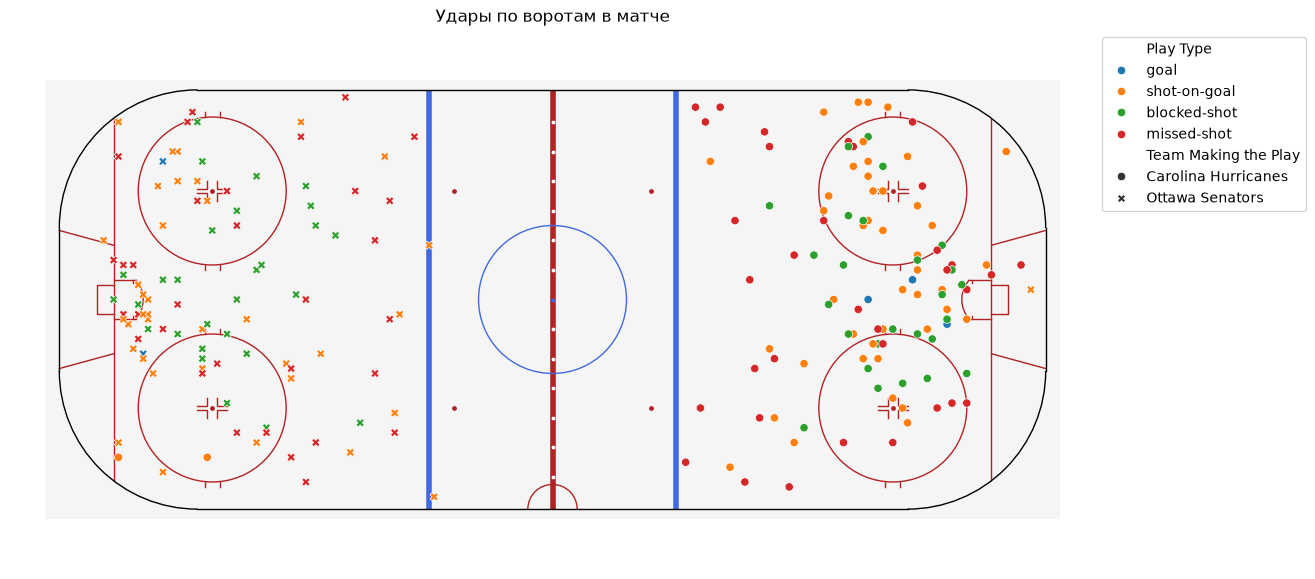

In [40]:
plt.figure(figsize=(14, 7))
plot_rink()
sns.scatterplot(data=max_game_shots, x='X Coordinate on the Ice Rink', y='Y Coordinate on the Ice Rink', hue='Play Type', style='Team Making the Play', hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'])
plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
plt.axis('equal')
plt.axis('off')
plt.title('Удары по воротам в матче')

### 16

In [41]:
goals = events[events['Play Type'] == 'goal']
top_scorers = goals['Player in the Event #1'].value_counts()
top_scorers.nlargest(10, keep='all')

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Matt Boldy           7
Mark Stone           7
Name: count, dtype: int64

### 17

Голевые передачи записаны в двух столбцах: Player in the Event #2 и Player in the Event #3. Объединим их в один, посчитаем, сколько раз встречается каждый игрок и выведем топ игроков.

In [42]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']])
top_assists = assists.value_counts()
top_assists.nlargest(10, keep='all')

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

### 18

Соберём голы и передачи каждого игрока в одну таблицу. У игроков без голов или без передач будет NaN, заменим его нулём.

In [43]:
points = pd.DataFrame({'Goals': top_scorers, 'Assists': top_assists}).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']
points.nlargest(10, 'Points', keep='all')

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Lane Hutson,3,13,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16


### 19

Посчитаем для каждого игрока броски в створ (без голов) и число сыгранных игр. Считаем игру сыгранной, если игрок хотя бы раз был на льду.

In [44]:
shots_on_goal = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
shooters = pd.DataFrame({
    'Shots': shots_on_goal['Player in the Event #1'].value_counts(),
    'Games': players.groupby('value')['Game ID'].nunique(),
}).fillna(0)
shooters['Shots per Game'] = shooters['Shots'] / shooters['Games']
shooters.nlargest(10, 'Shots per Game', keep='all')

,Shots,Games,Shots per Game
Jason Robertson,30.0,6,5.000000
Dylan Guenther,27.0,6,4.500000
Nikita Kucherov,31.0,7,4.428571
Matt Boldy,48.0,11,4.363636
Quinton Byfield,17.0,4,4.250000
Darren Raddysh,28.0,7,4.000000
Joel Eriksson Ek,24.0,6,4.000000
Alex Laferriere,15.0,4,3.750000
David Pastrnak,22.0,6,3.666667
Nathan MacKinnon,47.0,13,3.615385


### 20

Посчитаем для каждого игрока силовые приёмы и число сыгранных игр и выведем 10 рекордсменов.

In [45]:
hits = events[events['Play Type'] == 'hit']
hitters = pd.DataFrame({
    'Hits': hits['Player in the Event #1'].value_counts(),
    'Games': players.groupby('value')['Game ID'].nunique(),
}).fillna(0)
hitters['Hits per Game'] = hitters['Hits'] / hitters['Games']
hitters.nlargest(10, 'Hits per Game', keep='all')

,Hits,Games,Hits per Game
Lawson Crouse,38.0,6,6.333333
Alex Turcotte,6.0,1,6.000000
Alexander Petrovic,6.0,1,6.000000
Yakov Trenin,51.0,9,5.666667
Dylan Cozens,22.0,4,5.500000
Vasily Podkolzin,32.0,6,5.333333
Carl Grundstrom,15.0,3,5.000000
Ivan Barbashev,110.0,22,5.000000
Marcus Foligno,55.0,11,5.000000
Owen Tippett,29.0,6,4.833333
